# Symmetric Gaussian ansatz for the self-consistent prior (analytical, step 1)

Analytical treatment of the self-consistent prior for the 3-state / 3-signal example, per step 1 of `CLAUDE.md`. All methods are in `self_consistent_symmetric_ansatz.py`; this notebook holds parameters, execution, and visualization.

**Ansatz.** Each state-conditioned prior is a single Gaussian, $p_s = \mathcal N(\mu_s, C_s)$, and $p = \tfrac13\sum_s p_s$. We work in a symmetry-adapted orthonormal basis of $H$,

$$z_1 = \frac{\ell_{S1}-\ell_{S2}}{\sqrt2}, \qquad z_2 = \frac{2\ell_H-\ell_{S1}-\ell_{S2}}{\sqrt6},$$

in which the sickness swap (S1 $\leftrightarrow$ S2 together with Cough $\leftrightarrow$ Scratch) is the reflection $z_1\to-z_1$. The swap-symmetric, shared-covariance family has parameters $(h, a, b, c_1, c_2)$:

$$\mu_H = (0, h), \quad \mu_{S1} = (a, b), \quad \mu_{S2} = (-a, b), \quad C = \mathrm{diag}(c_1, c_2).$$

*(Note: other notebooks in this repo use the basis $\big((1,-1,0)/\sqrt2,\ (1,1,-2)/\sqrt6\big)$; the change of basis only affects plotting coordinates.)*

**Denoiser.** For a Gaussian-mixture prior, $F_p$ is a softmax-weighted average of affine maps: with responsibilities $r_k(y)\propto \mathcal N(y;\mu_k, C_k+\Sigma)$ and gains $G_k = C_k(C_k+\Sigma)^{-1}$,

$$F_p(y) = \sum_k r_k(y)\,\big[\mu_k + G_k(y-\mu_k)\big], \qquad DF_p(y) = \mathrm{Cov}_p(L\mid Y=y)\,\Sigma^{-1},$$

with $\Sigma = \sigma^2 I$ on $H$.

**Moment equations.** With the geometric age distribution (Eq. 37 of the notes), the law of the input to the denoiser under state $s$ is the 6-component Gaussian mixture $Y_s = \hat L_s' + \delta_x + \varepsilon$ with $\hat L_s' = 0$ w.p. $1-\lambda$ and $\hat L_s' \sim \mathcal N(\mu_s, C_s)$ w.p. $\lambda$, $x\sim P(x\mid s)$. Self-consistency projected onto the ansatz requires, for each state,

$$\mu_s = \mathbb E[F_p(Y_s)], \qquad C_s = \mathrm{Cov}[F_p(Y_s)],$$

followed by symmetrization (and covariance sharing). The expectations are Gauss–Hermite quadratures; the fixed point is found by damped iteration with continuation in $\sigma$.

**Bifurcation diagnostics.** (i) top eigenvalue of $DF_p$ at the inter-sickness midpoint $(0,b)$ (local expansion $\Leftrightarrow$ gain $>1$); (ii) spectrum of the linearized moment map, split into swap-symmetric and antisymmetric blocks; (iii) fixed points of the reduced skeleton slice $z_1 \mapsto [F_p((z_1,b)+\Delta_s)]_1$.

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

import self_consistent_symmetric_ansatz as ssa

LIKELIHOOD = np.array([
    [0.70, 0.20, 0.20],
    [0.15, 0.60, 0.20],
    [0.15, 0.20, 0.60],
])  # L[x, s] = P(x | S=s); x in {Whistle, Cough, Scratch}
AGE_LAMBDA = 0.9   # geometric continuation probability lambda
SIGMA_REF = 0.15   # reference internal-noise scale (matches grid/GMM solver runs)
GH_ORDER = 24      # Gauss-Hermite order per axis
DAMPING = 0.6
TOLERANCE = 1e-8

DISPLACEMENTS = ssa.signal_displacements(LIKELIHOOD)
DRIFTS = ssa.state_drifts(LIKELIHOOD, DISPLACEMENTS)
print("swap-symmetric likelihood:", ssa.is_swap_symmetric(LIKELIHOOD))
print("delta_x (z1, z2):\n", np.round(DISPLACEMENTS, 4))
print("Delta_s (z1, z2):\n", np.round(DRIFTS, 4))

swap-symmetric likelihood: True
delta_x (z1, z2):
 [[ 0.      1.0229]
 [ 0.7768 -0.6834]
 [-0.7768 -0.6834]]
Delta_s (z1, z2):
 [[ 0.      0.511 ]
 [ 0.3107 -0.3421]
 [-0.3107 -0.3421]]


## Geometry in the symmetry-adapted basis

Whistle moves straight up the healthy axis; Cough and Scratch are mirror images. Conditional on Healthy, the $z_1$ (sickness log-odds) drift is exactly zero.

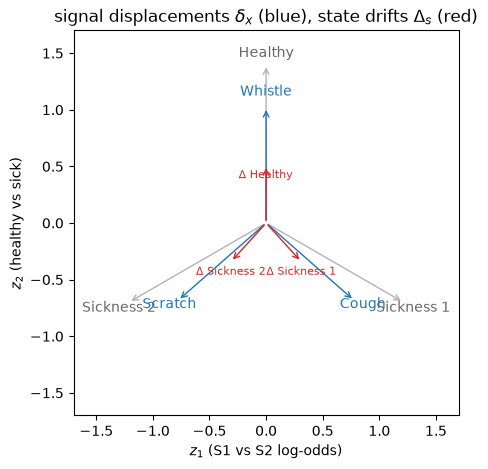

In [2]:
rays = ssa.state_directions()
fig, ax = plt.subplots(figsize=(5.5, 5))
for ray, name in zip(rays, ssa.STATES):
    ax.annotate("", xy=1.4 * ray, xytext=(0, 0),
                arrowprops=dict(arrowstyle="->", color="0.7"))
    ax.annotate(name, xy=1.5 * ray, ha="center", va="center", color="0.4")
for vec, name in zip(DISPLACEMENTS, ssa.SIGNALS):
    ax.annotate("", xy=vec, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="C0"))
    ax.annotate(name, xy=1.1 * vec, ha="center", color="C0")
for vec, name in zip(DRIFTS, ssa.STATES):
    ax.annotate("", xy=vec, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="C3"))
    ax.annotate(f"$\\Delta$ {name}", xy=vec + [0, -0.12], ha="center", color="C3", fontsize=8)
ax.set_xlim(-1.7, 1.7); ax.set_ylim(-1.7, 1.7); ax.set_aspect("equal")
ax.set_xlabel("$z_1$ (S1 vs S2 log-odds)"); ax.set_ylabel("$z_2$ (healthy vs sick)")
ax.set_title("signal displacements $\\delta_x$ (blue), state drifts $\\Delta_s$ (red)")
plt.show()

## Sanity checks

The closed-form denoiser against the one in `self_consistent_gmm_solver.py`; the analytic Jacobian $DF_p = \mathrm{Cov}_p(L\mid Y)/\sigma^2$ against finite differences; and the quadrature moment map against quadrature refinement and brute-force Monte Carlo.

In [3]:
import self_consistent_gmm_solver as gmm_solver

rng = np.random.default_rng(0)
ansatz0 = ssa.bayes_ansatz(LIKELIHOOD, DISPLACEMENTS, AGE_LAMBDA)
points = rng.normal(0.0, 5.0, (200, 2))
mixture = gmm_solver.GaussianMixture(np.ones(3) / 3, ansatz0.means, ansatz0.covariances)
print("denoiser vs gmm-solver module:",
      np.max(np.abs(ssa.denoise(points, ansatz0, SIGMA_REF)
                    - gmm_solver.gmm_denoise(points, mixture, SIGMA_REF))))

step = 1e-6
jacobians = ssa.denoiser_jacobian(points[:20], ansatz0, SIGMA_REF)
fd = np.stack([np.column_stack([
    (ssa.denoise(point + step * np.eye(2)[j], ansatz0, SIGMA_REF)[0]
     - ssa.denoise(point - step * np.eye(2)[j], ansatz0, SIGMA_REF)[0]) / (2 * step)
    for j in range(2)]) for point in points[:20]])
print("DF_p vs finite differences:", np.max(np.abs(jacobians - fd)))

means_quad, covs_quad = ssa.mapped_moments(
    ansatz0, LIKELIHOOD, DISPLACEMENTS, SIGMA_REF, AGE_LAMBDA, order=GH_ORDER)
means_fine, covs_fine = ssa.mapped_moments(
    ansatz0, LIKELIHOOD, DISPLACEMENTS, SIGMA_REF, AGE_LAMBDA, order=40)
print("quadrature order 24 vs 40: mean gap",
      np.max(np.abs(means_quad - means_fine)),
      "cov gap", np.max(np.abs(covs_quad - covs_fine)))

n_samples = 400_000
for state, name in enumerate(ssa.STATES):
    continue_mask = rng.random(n_samples) < AGE_LAMBDA
    previous = np.where(
        continue_mask[:, None],
        rng.multivariate_normal(ansatz0.means[state], ansatz0.covariances[state], n_samples),
        0.0)
    signals = rng.choice(3, n_samples, p=LIKELIHOOD[:, state])
    noisy = previous + DISPLACEMENTS[signals] + rng.normal(0.0, SIGMA_REF, (n_samples, 2))
    mapped = ssa.denoise(noisy, ansatz0, SIGMA_REF)
    print(f"Monte-Carlo check, {name:11s}: mean gap "
          f"{np.max(np.abs(mapped.mean(axis=0) - means_quad[state])):.4f}, "
          f"cov gap {np.max(np.abs(np.cov(mapped.T) - covs_quad[state])):.4f}")

denoiser vs gmm-solver module: 8.881784197001252e-15
DF_p vs finite differences: 6.886896053437397e-09
quadrature order 24 vs 40: mean gap 2.6797719598903313e-09 cov gap 9.797002320510728e-09


Monte-Carlo check, Healthy    : mean gap 0.0033, cov gap 0.0137
Monte-Carlo check, Sickness 1 : mean gap 0.0153, cov gap 0.0447


Monte-Carlo check, Sickness 2 : mean gap 0.0147, cov gap 0.0529


## Self-consistent ansatz at the reference parameters ($\sigma=0.15$, $\lambda=0.9$)

Damped fixed-point iteration from the noise-free Bayes moments. For reference, the converged marginal covariance trace was 51.85 (grid solver), 50.86 ($K=15$ GMM), 50.88 (conditional GMM).

free parameters: {'h': 5.0795, 'a': 3.0675, 'b': -3.406, 'c1': 8.756, 'c2': 19.7839}
marginal covariance trace: 50.81
midpoint gain: 0.999849
bimodality ratio a/sqrt(c1): 1.037


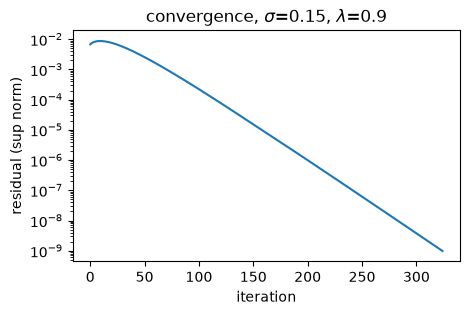

with the shared-covariance constraint relaxed (per-state C_s):
  Healthy     mean [0.    5.088]  cov [ 1.73  0.    0.   29.3 ]
  Sickness 1  mean [ 3.085 -3.411]  cov [ 12.28 -10.5  -10.5   15.03]
  Sickness 2  mean [-3.085 -3.411]  cov [12.28 10.5  10.5  15.03]


In [4]:
solution, history = ssa.solve_ansatz(LIKELIHOOD, SIGMA_REF, AGE_LAMBDA,
                                     damping=DAMPING, order=GH_ORDER,
                                     tolerance=1e-9, max_iterations=2000)
params = ssa.free_parameters(solution)
mean, covariance = ssa.mixture_moments(solution)
print("free parameters:", {key: round(value, 4) for key, value in params.items()})
print(f"marginal covariance trace: {np.trace(covariance):.2f}")
print(f"midpoint gain: {ssa.midpoint_gain(solution, SIGMA_REF):.6f}")
print(f"bimodality ratio a/sqrt(c1): {params['a'] / np.sqrt(params['c1']):.3f}")

fig, ax = plt.subplots(figsize=(5, 3))
ax.semilogy(history)
ax.set_xlabel("iteration"); ax.set_ylabel("residual (sup norm)")
ax.set_title(f"convergence, $\\sigma$={SIGMA_REF}, $\\lambda$={AGE_LAMBDA}")
plt.show()

solution_ps, _ = ssa.solve_ansatz(LIKELIHOOD, SIGMA_REF, AGE_LAMBDA, damping=DAMPING,
                                  order=GH_ORDER, tolerance=1e-9, max_iterations=2000,
                                  shared_covariance=False)
print("with the shared-covariance constraint relaxed (per-state C_s):")
for state, name in enumerate(ssa.STATES):
    print(f"  {name:11s} mean {np.round(solution_ps.means[state], 3)}"
          f"  cov {np.round(solution_ps.covariances[state].ravel(), 2)}")

The trace lands within 2% of the grid/GMM solvers, so the crude $K=1$-per-state ansatz already captures the diffuse fixed point. Relaxing the shared covariance shows it is a real constraint: Healthy is narrow in $z_1$ and wide in $z_2$, while the sickness components carry a strong $z_1$–$z_2$ correlation.

## Portrait of the fixed point

Marginal density, local gain field (top eigenvalue of $DF_p$), and the denoiser displacement field.

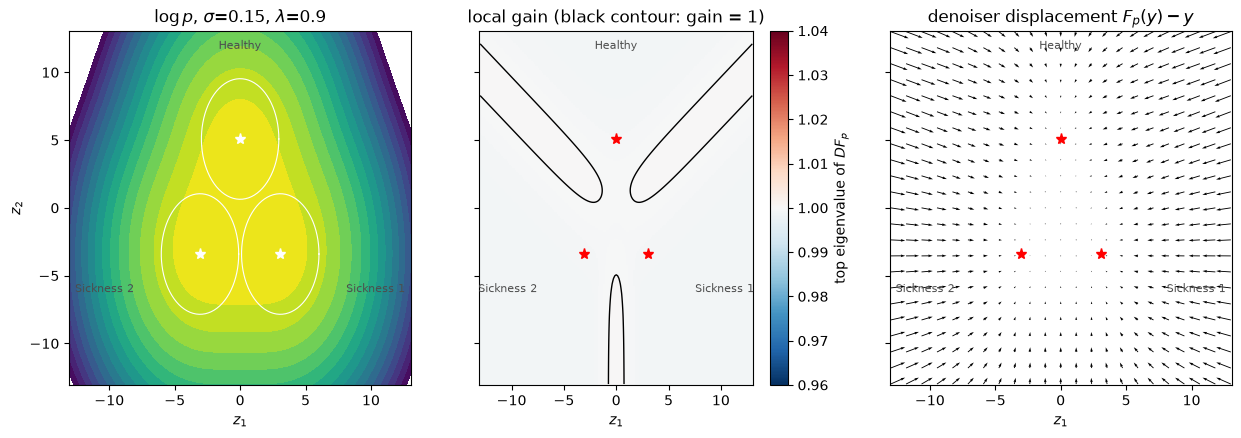

In [5]:
def portrait(ansatz, sigma, title, span=13.0, resolution=201):
    axis = np.linspace(-span, span, resolution)
    grid = np.stack(np.meshgrid(axis, axis), axis=-1).reshape(-1, 2)
    log_density = ssa.ansatz_logpdf(grid, ansatz).reshape(resolution, resolution)
    gain = np.linalg.eigvalsh(ssa.denoiser_jacobian(grid, ansatz, sigma))[:, -1]
    gain = gain.reshape(resolution, resolution)
    circle = np.stack([np.cos(np.linspace(0, 2 * np.pi, 80)),
                       np.sin(np.linspace(0, 2 * np.pi, 80))], axis=-1)

    fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharex=True, sharey=True)
    top = log_density.max()
    axes[0].contourf(axis, axis, log_density, levels=np.linspace(top - 8, top, 17),
                     cmap="viridis")
    for mean, cov in zip(ansatz.means, ansatz.covariances):
        axes[0].plot(*(mean + circle @ np.linalg.cholesky(cov).T).T, "w-", lw=0.8)
    axes[0].set_title(f"$\\log p$, {title}")

    image = axes[1].pcolormesh(axis, axis, gain, cmap="RdBu_r", vmin=0.96, vmax=1.04)
    axes[1].contour(axis, axis, gain, levels=[1.0], colors="k", linewidths=1.0)
    fig.colorbar(image, ax=axes[1], label="top eigenvalue of $DF_p$")
    axes[1].set_title("local gain (black contour: gain = 1)")

    coarse = np.linspace(-span, span, 23)
    quiver_grid = np.stack(np.meshgrid(coarse, coarse), axis=-1).reshape(-1, 2)
    displacement = ssa.denoise(quiver_grid, ansatz, sigma) - quiver_grid
    axes[2].quiver(quiver_grid[:, 0], quiver_grid[:, 1],
                   displacement[:, 0], displacement[:, 1], angles="xy")
    axes[2].set_title("denoiser displacement $F_p(y) - y$")

    for ax in axes:
        ax.plot(ansatz.means[:, 0], ansatz.means[:, 1], "w*" if ax is axes[0] else "r*",
                markersize=8, linestyle="none")
        for ray, name in zip(ssa.state_directions(), ssa.STATES):
            ax.annotate(name, xy=0.92 * span * ray, ha="center", va="center",
                        color="0.3", fontsize=8)
        ax.set_xlabel("$z_1$")
    axes[0].set_ylabel("$z_2$")
    plt.show()


portrait(solution, SIGMA_REF, f"$\\sigma$={SIGMA_REF}, $\\lambda$={AGE_LAMBDA}")

The gain is just *below* 1 in a band around the inter-sickness midline — locally near-neutral, nowhere expanding. The deterministic skeleton $\ell \mapsto F_p(\ell+\Delta_s)$ correspondingly has a single, far-field fixed point per state (the weak $1-\text{gain} \sim 10^{-3}$ contraction only balances the drift hundreds of units out), and no interior bistability.

## Continuation in $\sigma$ along the symmetric branch ($\lambda = 0.9$)

For each $\sigma$: solve, then record the ansatz parameters, the midpoint gain, the swap-symmetric / antisymmetric spectral radii of the linearized moment map, and the marginal trace.

In [6]:
SIGMAS_MAIN = np.concatenate([np.arange(0.05, 0.61, 0.05),
                              [0.62, 0.64, 0.66, 0.68, 0.69],
                              [0.70, 0.80, 0.90, 1.00, 1.05, 1.10, 1.20]])
records = ssa.bifurcation_scan(LIKELIHOOD, SIGMAS_MAIN, AGE_LAMBDA, order=GH_ORDER,
                               damping=DAMPING, tolerance=TOLERANCE,
                               max_iterations=6000)

sigma  0.050 | iters 241 | midpoint gain   1.000 | antisym radius  0.903 | healthy FPs 1


sigma  0.100 | iters 261 | midpoint gain   1.000 | antisym radius  0.906 | healthy FPs 1


sigma  0.150 | iters 274 | midpoint gain   1.000 | antisym radius  0.909 | healthy FPs 1


sigma  0.200 | iters 285 | midpoint gain   1.000 | antisym radius  0.912 | healthy FPs 1


sigma  0.250 | iters 296 | midpoint gain   1.000 | antisym radius  0.915 | healthy FPs 1


...

sigma  0.900 | iters 580 | midpoint gain   0.949 | antisym radius  1.003 | healthy FPs 1


sigma  1.000 | iters 1271 | midpoint gain   0.910 | antisym radius  1.004 | healthy FPs 1


sigma  1.050 | iters 188 | midpoint gain   0.000 | antisym radius  1.000 | healthy FPs 1


sigma  1.100 | iters   1 | midpoint gain   0.000 | antisym radius  1.000 | healthy FPs 1


sigma  1.200 | iters   1 | midpoint gain   0.000 | antisym radius  1.000 | healthy FPs 1


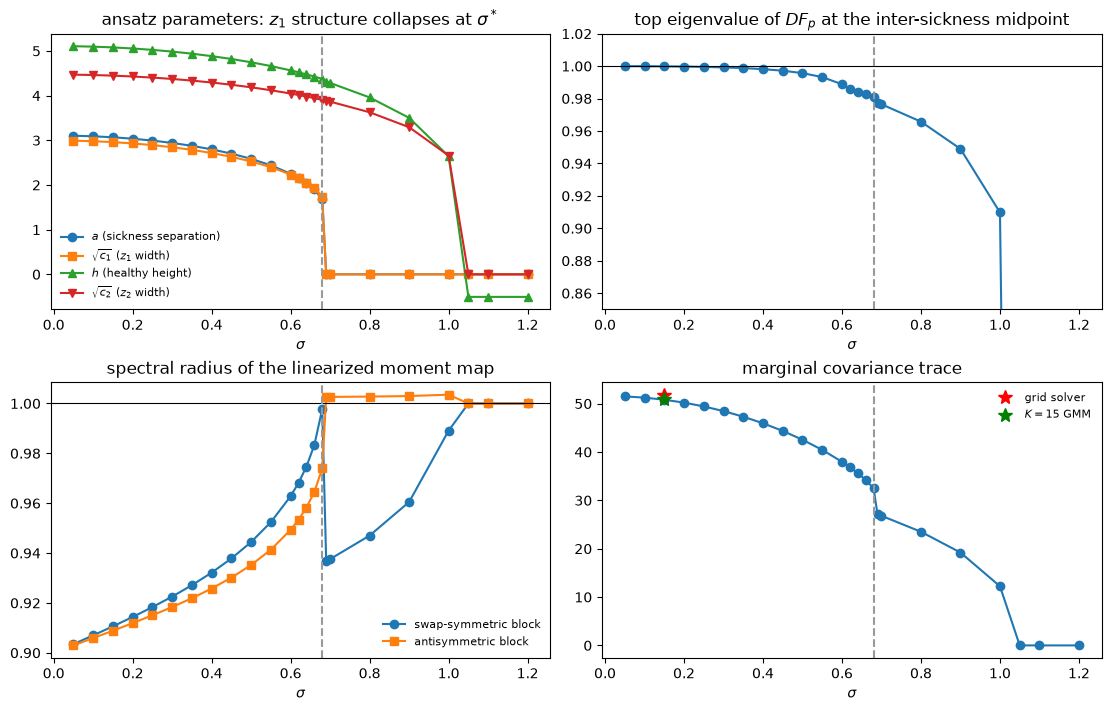

last sigma with z1 structure: sigma* = 0.68


In [7]:
sigmas = np.array([record["sigma"] for record in records])
values = {key: np.array([record["params"][key] for record in records])
          for key in ["h", "a", "b", "c1", "c2"]}
midpoint_gains = np.array([record["midpoint_gain"] for record in records])
symmetric_radii = np.array([record["symmetric_radius"] for record in records])
antisymmetric_radii = np.array([record["antisymmetric_radius"] for record in records])
traces = np.array([record["marginal_trace"] for record in records])
sigma_star = sigmas[np.flatnonzero(values["a"] > 1e-6)[-1]]

fig, axes = plt.subplots(2, 2, figsize=(11, 7), constrained_layout=True)
ax = axes[0, 0]
ax.plot(sigmas, values["a"], "o-", label="$a$ (sickness separation)")
ax.plot(sigmas, np.sqrt(values["c1"]), "s-", label="$\\sqrt{c_1}$ ($z_1$ width)")
ax.plot(sigmas, values["h"], "^-", label="$h$ (healthy height)")
ax.plot(sigmas, np.sqrt(values["c2"]), "v-", label="$\\sqrt{c_2}$ ($z_2$ width)")
ax.axvline(sigma_star, color="0.6", ls="--")
ax.set_xlabel("$\\sigma$"); ax.legend(fontsize=8)
ax.set_title("ansatz parameters: $z_1$ structure collapses at $\\sigma^*$")

ax = axes[0, 1]
ax.plot(sigmas, midpoint_gains, "o-")
ax.axhline(1.0, color="k", lw=0.8); ax.axvline(sigma_star, color="0.6", ls="--")
ax.set_ylim(0.85, 1.02); ax.set_xlabel("$\\sigma$")
ax.set_title("top eigenvalue of $DF_p$ at the inter-sickness midpoint")

ax = axes[1, 0]
ax.plot(sigmas, symmetric_radii, "o-", label="swap-symmetric block")
ax.plot(sigmas, antisymmetric_radii, "s-", label="antisymmetric block")
ax.axhline(1.0, color="k", lw=0.8); ax.axvline(sigma_star, color="0.6", ls="--")
ax.set_xlabel("$\\sigma$"); ax.legend(fontsize=8)
ax.set_title("spectral radius of the linearized moment map")

ax = axes[1, 1]
ax.plot(sigmas, traces, "o-")
ax.plot([0.15], [51.85], "r*", markersize=10, label="grid solver")
ax.plot([0.15], [50.86], "g*", markersize=10, label="$K=15$ GMM")
ax.axvline(sigma_star, color="0.6", ls="--")
ax.set_xlabel("$\\sigma$"); ax.legend(fontsize=8)
ax.set_title("marginal covariance trace")
plt.show()
print(f"last sigma with z1 structure: sigma* = {sigma_star}")

**No pitchfork in $\sigma$: a saddle-node collapse instead.** The midpoint gain stays *below* 1 along the whole branch (approaching 1 as $\sigma\to0$). What terminates the branch at $\sigma^*\approx0.68$ is the swap-*symmetric* block of the moment-map spectrum reaching 1: the sickness separation $a$ and $z_1$ width $c_1$ vanish together and the prior collapses onto the $z_1=0$ line — the observer's prior stops discriminating the two sicknesses at all. The line-supported branch persists (with shrinking $h, c_2$) until it collapses to the point-mass family at $\sigma^{**}\approx1.05$. Note the antisymmetric radius sits at $\approx 1$ on the collapsed branch: that is the neutral translation mode of the degenerate (line-supported) solutions.

Both degenerate solutions are convex-hull traps (support cannot expand under $F_p$), so where the diffuse branch exists the system is bistable:

In [8]:
diffuse = records[int(np.argmin(np.abs(sigmas - 0.60)))]["ansatz"]

inflated = diffuse.copy()
inflated.means[:, 0] *= 1.5
inflated.covariances[:, 0, 0] *= 2.0
forced, _ = ssa.solve_ansatz(LIKELIHOOD, 0.72, AGE_LAMBDA, init=inflated, damping=0.3,
                             order=GH_ORDER, tolerance=TOLERANCE, max_iterations=8000)
print("sigma = 0.72, inflated diffuse init ->",
      {key: round(value, 6) for key, value in ssa.free_parameters(forced).items()})

degenerate = diffuse.copy()
degenerate.means[:, 0] = 0.0
degenerate.covariances[:, 0, :] = 0.0
degenerate.covariances[:, :, 0] = 0.0
degenerate.covariances[:, 0, 0] = 1e-12
trapped, _ = ssa.solve_ansatz(LIKELIHOOD, 0.30, AGE_LAMBDA, init=degenerate,
                              damping=DAMPING, order=GH_ORDER, tolerance=TOLERANCE,
                              max_iterations=2000)
print("sigma = 0.30, z1-degenerate init  ->",
      {key: round(value, 6) for key, value in ssa.free_parameters(trapped).items()})

sigma = 0.72, inflated diffuse init -> {'h': 4.226526, 'a': 0.0, 'b': -2.994711, 'c1': 0.0, 'c2': 14.618957}


sigma = 0.30, z1-degenerate init  -> {'h': 4.976108, 'a': 0.0, 'b': -3.357843, 'c1': 0.0, 'c2': 19.129574}


Even a fattened initial condition finds no diffuse solution beyond $\sigma^*$ (saddle-node, not a mere stability change), and at small $\sigma$ the $z_1$-degenerate line solution is locally stable — bistability and hysteresis below $\sigma^*$.

## The bifurcation is in $\lambda$

The midpoint gain at $\sigma=0.15$ as a function of the belief lifetime parameter $\lambda$, and gain-vs-$\sigma$ curves for three lifetimes.

In [9]:
LAMBDAS = np.concatenate([np.arange(0.80, 0.905, 0.02),
                          [0.91, 0.92, 0.93, 0.94, 0.95, 0.96]])
lambda_records = []
previous = None
for age_lambda in LAMBDAS:
    ansatz_l, history_l = ssa.solve_ansatz(LIKELIHOOD, SIGMA_REF, age_lambda,
                                           init=previous, damping=0.5, order=GH_ORDER,
                                           tolerance=TOLERANCE, max_iterations=8000)
    lambda_records.append((age_lambda, ansatz_l))
    previous = ansatz_l
    print(f"lambda {age_lambda:.2f} | iters {len(history_l):4d} "
          f"| midpoint gain {ssa.midpoint_gain(ansatz_l, SIGMA_REF):.6f}")

lambda_gains = np.array([ssa.midpoint_gain(ansatz_l, SIGMA_REF)
                         for _, ansatz_l in lambda_records])
crossing = np.flatnonzero((lambda_gains[:-1] < 1) & (lambda_gains[1:] >= 1))[0]
lambda_c = np.interp(1.0, lambda_gains[crossing:crossing + 2],
                     LAMBDAS[crossing:crossing + 2])
print(f"\nmidpoint gain crosses 1 at lambda_c ~ {lambda_c:.3f}")

lambda 0.80 | iters  168 | midpoint gain 0.997656


lambda 0.82 | iters  213 | midpoint gain 0.998275


lambda 0.84 | iters  243 | midpoint gain 0.998807


lambda 0.86 | iters  283 | midpoint gain 0.999250


lambda 0.88 | iters  336 | midpoint gain 0.999598


...

lambda 0.92 | iters  510 | midpoint gain 1.000007


lambda 0.93 | iters  592 | midpoint gain 1.000052


lambda 0.94 | iters  701 | midpoint gain 1.000076


lambda 0.95 | iters  856 | midpoint gain 1.000083


lambda 0.96 | iters 1093 | midpoint gain 1.000075

midpoint gain crosses 1 at lambda_c ~ 0.919


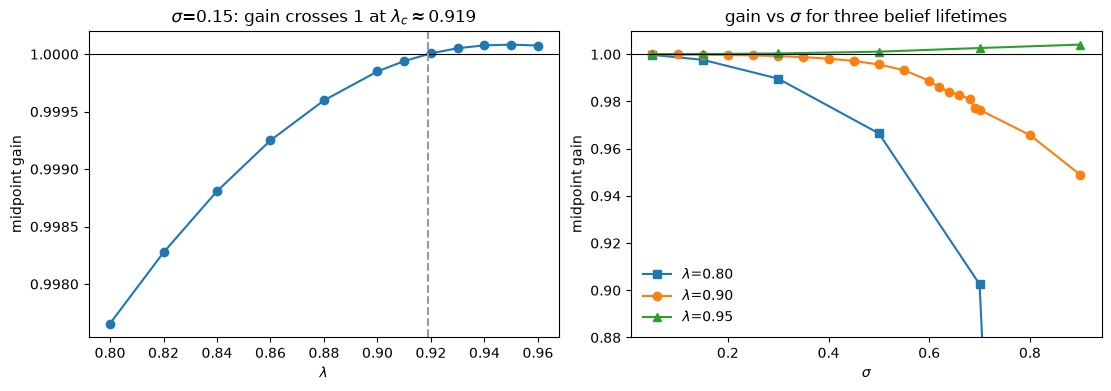

In [10]:
SIGMAS_COARSE = [0.05, 0.15, 0.30, 0.50, 0.70, 0.90]
gain_curves = {}
for age_lambda in [0.80, 0.95]:
    previous, row = None, []
    for sigma in SIGMAS_COARSE:
        ansatz_c, _ = ssa.solve_ansatz(LIKELIHOOD, sigma, age_lambda, init=previous,
                                       damping=0.5, order=GH_ORDER,
                                       tolerance=TOLERANCE, max_iterations=8000)
        row.append(ssa.midpoint_gain(ansatz_c, sigma))
        previous = ansatz_c
    gain_curves[age_lambda] = row

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
axes[0].plot(LAMBDAS, lambda_gains, "o-")
axes[0].axhline(1.0, color="k", lw=0.8)
axes[0].axvline(lambda_c, color="0.6", ls="--")
axes[0].set_xlabel("$\\lambda$"); axes[0].set_ylabel("midpoint gain")
axes[0].set_title(f"$\\sigma$={SIGMA_REF}: gain crosses 1 at "
                  f"$\\lambda_c\\approx${lambda_c:.3f}")
axes[1].plot(SIGMAS_COARSE, gain_curves[0.80], "s-", label="$\\lambda$=0.80")
axes[1].plot(sigmas[sigmas <= 0.95], midpoint_gains[sigmas <= 0.95], "o-",
             label="$\\lambda$=0.90")
axes[1].plot(SIGMAS_COARSE, gain_curves[0.95], "^-", label="$\\lambda$=0.95")
axes[1].axhline(1.0, color="k", lw=0.8)
axes[1].set_xlabel("$\\sigma$"); axes[1].set_ylabel("midpoint gain")
axes[1].set_ylim(0.88, 1.01)
axes[1].set_title("gain vs $\\sigma$ for three belief lifetimes")
axes[1].legend()
plt.show()

For $\lambda>\lambda_c$ the gain exceeds 1 for *every* $\sigma$ up to that branch's collapse (and grows with $\sigma$): once beliefs live long enough, the inter-sickness midline is locally expanding at any internal-noise level on this branch. The portrait at $\lambda=0.95$ shows the expanding strip (red, inside the black gain = 1 contour):

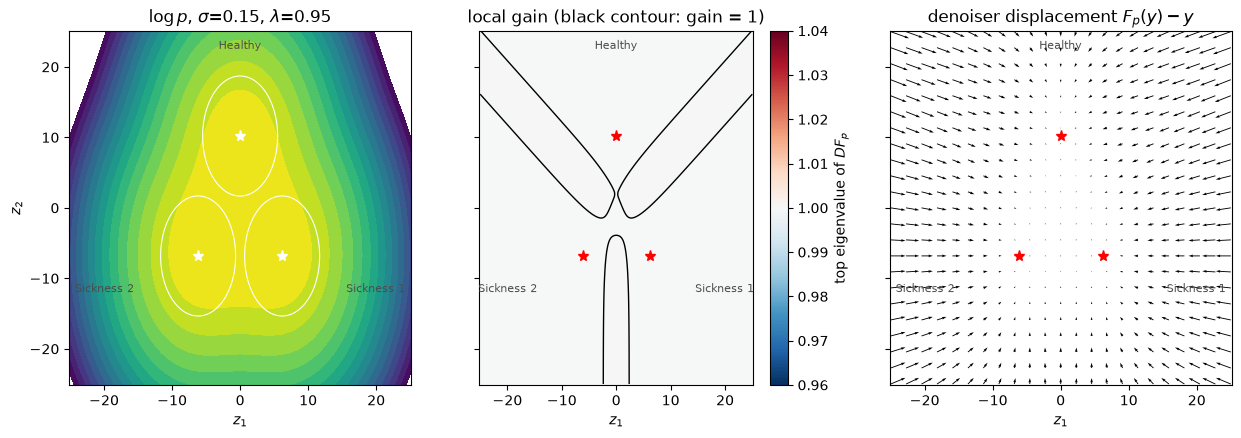

In [11]:
solution95 = lambda_records[-2][1]  # lambda = 0.95
portrait(solution95, SIGMA_REF, f"$\\sigma$={SIGMA_REF}, $\\lambda$=0.95", span=25.0)

## Pitchfork of the reduced midline skeleton

Conditional on Healthy, $z_1$ has zero mean drift, so the reduced slice map $f(z_1) = [F_p((z_1, b) + \Delta_H)]_1$ captures the effective double-well. Below $\lambda_c$ it has a single stable fixed point at $z_1=0$; above, $z_1=0$ turns unstable and two mirror attractors $\pm z_1^*$ appear — noise alone decides which sickness a Healthy observer leans toward.

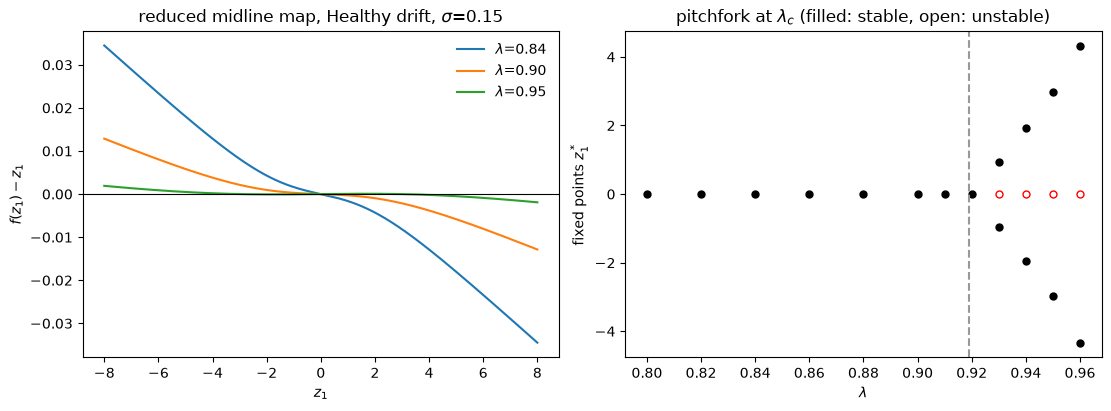

lambda=0.95 Healthy midline fixed points: [-2.97 -0.    2.97] slopes: [0.99987 1.00007 0.99987]
lambda=0.95 Sickness-1 midline fixed points within |z1|<15: []


In [12]:
z1_axis = np.linspace(-8, 8, 401)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)

for age_lambda, ansatz_l in lambda_records:
    if round(age_lambda, 2) in (0.84, 0.90, 0.95):
        displacement = ssa.midline_map(z1_axis, ansatz_l, SIGMA_REF, DRIFTS[0]) - z1_axis
        axes[0].plot(z1_axis, displacement, label=f"$\\lambda$={age_lambda:.2f}")
axes[0].axhline(0.0, color="k", lw=0.8)
axes[0].set_xlabel("$z_1$"); axes[0].set_ylabel("$f(z_1) - z_1$")
axes[0].set_title("reduced midline map, Healthy drift, $\\sigma$=0.15")
axes[0].legend()

for age_lambda, ansatz_l in lambda_records:
    roots, slopes = ssa.midline_fixed_points(ansatz_l, SIGMA_REF, DRIFTS[0], span=10.0)
    for root, slope in zip(roots, slopes):
        stable = abs(slope) < 1
        axes[1].plot(age_lambda, root, "ko" if stable else "ro",
                     mfc="k" if stable else "none", markersize=5)
axes[1].axvline(lambda_c, color="0.6", ls="--")
axes[1].set_xlabel("$\\lambda$"); axes[1].set_ylabel("fixed points $z_1^*$")
axes[1].set_title("pitchfork at $\\lambda_c$ (filled: stable, open: unstable)")
plt.show()

roots95, slopes95 = ssa.midline_fixed_points(solution95, SIGMA_REF, DRIFTS[0], span=10.0)
print("lambda=0.95 Healthy midline fixed points:", np.round(roots95, 3),
      "slopes:", np.round(slopes95, 5))
roots_s1, _ = ssa.midline_fixed_points(solution95, SIGMA_REF, DRIFTS[1], span=15.0)
print("lambda=0.95 Sickness-1 midline fixed points within |z1|<15:",
      np.round(roots_s1, 3))

Under $S=$ Sickness 1 the slice map has *no* interior fixed points: the $z_1$ drift toward S1 ($+0.31$ per step) dominates the weak double-well force ($|f'-1|\lesssim3\times10^{-3}$), so the ansatz predicts no stable *mistaken* believers at these parameters.

## Findings

1. **Validation.** At $(\sigma, \lambda) = (0.15, 0.9)$ the ansatz reproduces the diffuse self-consistent prior found by the grid and GMM solvers: marginal trace $\approx 50.8$ vs 51.85 / 50.86, with $(h, a, b, c_1, c_2) \approx (5.08,\ 3.07,\ -3.41,\ 8.76,\ 19.78)$.
2. **No polarization in $\sigma$ at $\lambda=0.9$ — self-tuned marginality.** The midpoint gain stays below 1 on the whole branch and approaches 1 as $\sigma\to0$ (0.99985 at $\sigma=0.15$): self-consistency keeps the component widths at the edge of bimodality in the sickness log-odds ($a/\sqrt{c_1}\approx1.04$), so the hypothesized eigenvalue crossing in $\sigma$ never happens at this $\lambda$.
3. **The branch instead ends in a saddle-node collapse.** At $\sigma^*\approx0.68$ the swap-symmetric spectral radius of the linearized moment map reaches 1 and $(a, c_1)\to0$: the prior collapses onto the $z_1=0$ line, losing all sickness discrimination; the line branch collapses further to the point-mass family at $\sigma^{**}\approx1.05$. The degenerate solutions are convex-hull traps, stable at all $\sigma$, giving bistability and hysteresis below $\sigma^*$.
4. **The polarization bifurcation exists — in $\lambda$, not $\sigma$.** At $\sigma=0.15$ the midpoint gain crosses 1 at $\lambda_c\approx0.92$; beyond it the reduced Healthy-observer skeleton undergoes a pitchfork: $z_1=0$ destabilizes and two mirror attractors appear ($z_1^*\approx\pm3.0$ at $\lambda=0.95$). For $\lambda>\lambda_c$ the gain exceeds 1 for every $\sigma$ up to collapse — long belief lifetimes, not a special noise level, produce polarization on this branch.
5. **No stable mistaken believers** under a sickness state within the ansatz: state drift dominates the weak expansion.
6. **Caveats and next steps.** A single Gaussian per state can only signal the *onset* of polarization (local expansion), not its saturated bimodal shape, and the expansion above threshold is weak (gain $1.0001$–$1.004$). Cross-check with the grid solver (step 2) at $\lambda=0.95$ — the true $p_H$ should turn bimodal in $z_1$ there — and explore likelihoods with stronger inter-sickness contrast to fatten the effect.